# Module 1 · Partie 0 : Introduction au Data Mining & Machine Learning, et prise en main de R

**Analyse multivariée 2 : Data Mining & Machine Learning** — *Linear regression, Ridge and Lasso* (Prof. Hélène Soyeurt, année académique 2026-2027)

---

### Objectifs d'apprentissage
À la fin de ce notebook, tu sauras :
1. utiliser ce cours interactif (VS Code + noyau R) ;
2. situer le cours dans l'organisation générale (6 modules, examen) ;
3. définir **Data Mining**, **Machine Learning** et **chimiométrie**, et citer les définitions de Samuel et de Mitchell ;
4. décrire le processus **KDD** (*Knowledge Discovery in Data Base*) et ses étapes ;
5. distinguer **régression**, **classification** et **clustering**, ainsi que les méthodes **supervisées** et **non supervisées** ;
6. comprendre le contexte applicatif du module (analyse du lait par spectrométrie moyen infrarouge) et la structure des jeux de données ;
7. maîtriser les **commandes R de base** utilisées dans tout le module.

### Prérequis
Statistiques appliquées (STAT2004/STAT2005) et Analyse multivariée 1 (STAT1213). Pas de prérequis spécifique en R : les bases sont rappelées ici.

### Sommaire
- 0.1 Mode d'emploi du cours
- 0.2 Organisation du cours AM2
- 0.3 Data Mining et Machine Learning : définitions et histoire
- 0.4 Le processus KDD
- 0.5 Quel est l'objectif ? Régression, classification, clustering
- 0.6 Contexte applicatif : l'analyse du lait et les jeux de données du module
- 0.7 Rappels de R indispensables
- Récapitulatif

## 0.1 Mode d'emploi du cours

### Les notebooks du module 1

| Notebook | Contenu |
|---|---|
| `00_Introduction_et_prise_en_main` | Définitions, KDD, contexte, rappels R (**tu es ici**) |
| `01_Exploration_et_controle_des_donnees` | *Data check* : types de données, statistiques descriptives, valeurs aberrantes, colinéarité, mise à l'échelle, transformations |
| `02_Regression_lineaire_univariee` | Régression simple, moindres carrés, R², analyse des résidus |
| `03_Regression_lineaire_multivariee` | Forme matricielle, OLS, sur-ajustement, colinéarité |
| `04_Selection_de_variables` | Toutes les combinaisons, backward, forward, stepwise, importance relative |
| `05_Estimation_numerique_descente_de_gradient` | Fonction de coût, descente de gradient, *feature scaling* |
| `06_Regressions_penalisees` | Ridge, Lasso, Elastic Net (`glmnet`) |
| `07_TP_Homework1_acides_gras` | TP guidé : le homework 1 (acides gras saturés) |
| `08_Synthese_et_aide_memoire` | Synthèse, workflow complet, aide-mémoire |

### Utiliser le notebook dans VS Code
1. Ouvre le fichier `.ipynb` dans VS Code (extension **Jupyter** installée).
2. En haut à droite, clique sur **Select Kernel** → *Jupyter Kernel…* → **R (AM2)**.
3. Exécute une cellule avec **Shift + Entrée** (exécute et passe à la suivante) ou **Ctrl + Entrée** (exécute sans bouger).
4. Les cellules s'exécutent **dans l'ordre** : si une cellule utilise un objet créé plus haut, il faut avoir exécuté la cellule qui le crée. En cas de doute : *Restart* puis *Run All*.

### Les encadrés et les exercices
- > **Définition** : notion à connaître.
- > **Attention** : piège classique ou incohérence des sources.
- > **Complément** : explication pédagogique supplémentaire, qui va au-delà des slides.
- > **Fonction R** : description générale d'une fonction (signature, arguments, résultat).
- **Exercices** : une cellule `# À toi de jouer !` pour écrire ton code, puis une solution **repliable** (« Voir la solution »). Essaie toujours avant de déplier !

## 0.2 Organisation du cours AM2

Le cours comporte **6 modules**, chacun composé de **3 activités** (théorie, séance pratique, homework) :

| Module | Contenu | Professeur | Théorie | Séance pratique | Homework |
|---|---|---|---|---|---|
| 1 | Introduction, *Linear Regression*, *Ridge, Lasso & Elastic Net* | H. Soyeurt | 16-09-2026 (online) | 23-09-2026 (ZT1) | 06-oct |
| 2 | Validation, *Principal Component regression* (PCR), *Partial Least Square regression* (PLS) | H. Soyeurt | 6-10-2026 | 7-10-2026 | 13-oct |
| 3 | *Logistic regression* | Y. Brostaux | 13-10-2026 | 20-10-2026 | 02-nov |
| 4 | *Random Forest* | Y. Brostaux | 2-11-2026 | 9-11-2026 | 16-nov |
| 5 | *Discriminant analysis PLS*, *Support vector machine* (SVM) | J.A. Fernández Pierna | 16-11-2026 | 23-11-2026 | 01-déc |
| 6 | *Artificial neural network* (ANN) | H. Soyeurt | 30-11-2026 | 7-12-2026 | 13-déc |

Les séances pratiques sont assurées par Maxime Cornet.

- **Séance pratique** : faire l'exercice et le homework **avant** de poser des questions.
- **Examen** :
  - *open course*, **sans** modèle de langage (LM), **4 h** ;
  - analyse de données : **script + rapport**.

> **Complément** : comme l'examen consiste à produire un script R et un rapport, l'objectif de ce cours est double : comprendre la théorie **et** savoir écrire/interpréter du code R de façon autonome. Les encadrés sont là pour que tu saches réutiliser chaque fonction dans un autre contexte.

## 0.3 Data Mining et Machine Learning

### Contexte : les données massives
Les avancées technologiques permettent de collecter facilement beaucoup de données sur un individu (vivant ou non) : capteurs, observations visuelles, enquêtes… Ces données sont **hétérogènes** (quantitatives, qualitatives, répétées dans le temps et l'espace) et souvent **dépendantes entre elles**. Cet ensemble complexe, acquis rapidement et stocké en grand volume, est appelé **données massives** (*Big data*).

Autrefois, le facteur limitant était la puissance de calcul. Aujourd'hui, ce n'est plus le cas : l'enjeu est d'**extraire des connaissances pertinentes** de ces données. C'est l'objectif du Data Mining et du Machine Learning.

> **Définition : Data Mining**
> Le Data Mining vise à **découvrir des relations dans un jeu de données** à l'aide de techniques/méthodes issues de la **Statistique**, du **Machine Learning** et de la **gestion des données** (*Data Management*). Le but final est d'**extraire de l'information** d'un jeu de données et de la transformer en **information utile** pour différentes applications.
> Le terme englobe toutes les méthodes permettant d'extraire des connaissances à partir de données initiales apparemment non structurées ; le Data Mining utilise donc aussi des méthodes de Machine Learning.

> **Définition : Machine Learning**
> - **Arthur Lee Samuel** (1901-1990), en 1959 : le Machine Learning regroupe les méthodes qui donnent aux ordinateurs **la capacité d'apprendre sans avoir été explicitement programmés** pour cela.
> - **Tom Mitchell** (Carnegie Mellon University) introduit l'**apprentissage par l'expérience** :
>   *« A computer program is said to learn from experience **E** with respect to some task **T** and some performance measure **P**, if its performance on T, as measured by P, improves with experience E. »*

> **Définition : Chimiométrie** (*chemometrics*)
> Terme fréquent en sciences du vivant : sous-groupe du Data Mining (donc du ML) qui ne comprend que des **méthodes prédictives**, typiquement celles qui prédisent la teneur d'un composé à partir d'un **signal électromagnétique** dont les points de mesure adjacents sont **fortement corrélés**. C'est exactement notre cas (spectres moyen infrarouge du lait).

Dans ce cours, on utilise simplement le terme **Machine Learning** pour désigner l'ensemble de ces méthodes. Historiquement utilisé en marketing, finance, communication et assurance, le ML gagne les sciences du vivant avec les applications *Smart* : *Smart Health*, *Smart Cities*, *Smart Farming*…

### Exercice 0.1 : la définition de Mitchell
Dans l'exemple du module (prédire la teneur en lactoferrine du lait à partir de son spectre infrarouge), identifie **E**, **T** et **P**.

<details>
<summary><b>Voir la solution</b></summary>

- **T (tâche)** : prédire la teneur en lactoferrine (mg/L) d'un échantillon de lait à partir de son spectre MIR.
- **E (expérience)** : les échantillons pour lesquels on dispose à la fois du spectre et de la valeur de référence (dosage ELISA) : ici 178 échantillons.
- **P (performance)** : une mesure de la qualité des prédictions, par exemple le R² ou l'erreur quadratique moyenne (RMSE).

Le programme « apprend » si P s'améliore quand E augmente (plus d'échantillons de calibration).

</details>

### Petite histoire : ce n'est pas nouveau…

| Époque | Jalon |
|---|---|
| Avant J.-C. | Chine, Égypte (premiers recueils et traitements de données) |
| ~1800 | Probabilités (Bayes, Laplace) |
| ~1900 | Legendre : **moindres carrés** (*least squares*) |
| ~1930 | Fisher : **analyse de la variance** |
| ~1950 | Ordinateur, classification, **réseaux de neurones** |
| ~1960 | **Arbres de décision**, analyse des correspondances multiples |
| ~1980 | **KDD** (*Knowledge Discovery in Data Base*, © Data Mining), *Data Mining*, exploration de données |
| ~1990 | **Machine Learning** |

> **Complément** : la méthode que tu vas utiliser le plus dans ce module, les **moindres carrés**, date du début du XIXᵉ siècle (Legendre, 1805). Les régressions pénalisées (Ridge 1970, Lasso 1996) en sont des extensions modernes.

## 0.4 Le processus KDD (*Knowledge Discovery in Data Base*)

Le Machine Learning consiste à apprendre des connaissances à partir de données. Cet apprentissage doit être **structuré** dans un projet de data mining, appelé **KDD** (figure © Zentut, 2017) :

```
 Data ──Selection──> Target data ──Preprocessing──> Preprocessed data ──Transformation──> Transformed data
                                                                                              │
                                     Knowledge <──Interpretation/Evaluation── Patterns/Models <──Data mining
```

| Étape | Nom | Ce qu'on y fait |
|---|---|---|
| **0** | *Objective definition* | Définir précisément l'objectif : le sujet, la **population cible**, l'**unité statistique** étudiée. |
| **1** | *Selection* | Choisir les variables (*features*) nécessaires. Inventaire précis des variables disponibles ; certaines sont inutilisables (fiabilité, trop de données manquantes). Discussion avec des **experts du domaine** ; éventuellement mettre en place un **protocole d'acquisition**. Toujours tenir compte des données **réellement disponibles sur le terrain** quand le modèle sera utilisé. |
| **2** | *Preprocessing / Cleaning* | Nettoyer les données (tableau : enregistrements en lignes, champs en colonnes) : supprimer les lignes massivement manquantes, imputer (moyenne, médiane, classe la plus représentée…), créer de nouvelles variables (mois d'une date, ratios, recodage par niveaux d'intensité…). But : **homogénéiser** et **donner de la profondeur** au fichier. |
| **3** | *Transformation* (*Scale*) | Mettre les variables à une échelle appropriée : **standardisation** (étendue, moyenne, variance), conversion d'unités, **correction de ligne de base** pour les spectres… |
| **4** | *Data mining* (*Method choice*) | Appliquer la méthode de ML la plus adaptée à l'objectif → modèle. C'est l'étape de **calibration**. |
| **5** | *Interpretation / Evaluation* | Implémenter le modèle et évaluer ses performances sur un **jeu de test** contenant idéalement des **données indépendantes** : c'est la **validation**. |

Le processus est **itératif** : les résultats de la validation révèlent les faiblesses des étapes précédentes, qu'on améliore (manuellement ou automatiquement).

### Facteurs de succès d'un projet de data mining (Trufféry, 2011)
- des objectifs **précis, stratégiques et réalistes** ;
- la **richesse et la qualité** de l'information collectée ;
- la **collaboration** entre toutes les parties prenantes et le statisticien/data miner ;
- la **pertinence** des techniques de ML utilisées ;
- la **restitution correcte** de l'information générée et une bonne intégration dans le système d'information ;
- l'**analyse des résultats** et la prise en compte du **retour des utilisateurs**.

> **Complément** : les notebooks suivent le KDD. Le notebook 01 couvre les étapes 2-3 (*cleaning*, *scale*), les notebooks 02 à 06 l'étape 4 (*method choice*, calibration). La validation (étape 5) sera approfondie au module 2.

## 0.5 Quel est l'objectif ? Trois possibilités

| | **Régression** | **Classification** | **Clustering** |
|---|---|---|---|
| Variable à expliquer | **quantitative** | **qualitative** | aucune |
| But | **prédiction** (modélisation d'une tendance) | séparer les échantillons en **classes/groupes** connus | créer des **sous-groupes** à partir des similarités |
| Type de méthode | **supervisée** | **supervisée** | **non supervisée** |

> **Définition : supervisé / non supervisé**
> Une méthode est **supervisée** quand le modèle est construit à partir d'une **cible** à atteindre (la variable à expliquer, *y*). En **clustering**, il n'y a **pas de cible** : la méthode met en évidence les liens entre échantillons.

### Classification vs clustering : l'exemple des fruits
On dispose d'objets : une pomme, une orange, une myrtille, un cadeau rouge, une boîte orange… *Combien de clusters ?*
- Un algorithme **non supervisé** peut regrouper par **couleur** (rouge / orange / bleu : 3 clusters) ou par **forme** (ronds / carrés : 2 clusters). Le regroupement obtenu peut ensuite être interprété, mais on ne le choisit pas.
- Pour obtenir **les groupes que l'on veut**, on fournit une cible codée, par exemple en variables indicatrices 0/1 :

| Objet | Fruit | Autre | Cercle | Carré | Rouge | Orange | Bleu |
|---|---|---|---|---|---|---|---|
| pomme | 1 | 0 | 1 | 0 | 1 | 0 | 0 |
| orange | 1 | 0 | 1 | 0 | 0 | 1 | 0 |
| cadeau | 0 | 1 | 0 | 1 | 1 | 0 | 0 |
| myrtille | 1 | 0 | 1 | 0 | 0 | 0 | 1 |
| boîte | 0 | 1 | 0 | 1 | 0 | 1 | 0 |

On **force** la méthode à obtenir les groupes désirés (« fruit vs autres », « cercle vs carré », « rouge/orange/bleu ») → c'est de la **classification**.

### Les algorithmes
Une multitude de méthodes existe (carte © Mastery, 2017 : régression, régularisation, arbres de décision, bayésien, instance-based, clustering, réduction de dimension, réseaux de neurones, *deep learning*, ensembles…). Certaines ont été vues en **Statistiques appliquées** (régression linéaire) et en **Analyse multivariée 1** (ACP, clustering : méthodes non supervisées). **Ce cours se concentre sur les méthodes supervisées.** Dans ce module : *Ordinary Least Squares Regression*, *Linear Regression*, *Stepwise Regression*, *Ridge Regression*, *LASSO*, *Elastic Net*.

### Exercice 0.2 : régression, classification ou clustering ?
Pour chaque situation, indique le type d'objectif et si la méthode est supervisée :
1. Prédire la teneur en acides gras saturés du lait (g/dL) à partir du spectre MIR.
2. Prédire si une vache est atteinte de mammite (oui/non) à partir de son lait.
3. Regrouper des exploitations agricoles selon leurs pratiques, sans groupes définis à l'avance.
4. Attribuer la race (Holstein, Jersey, Blanc-Bleu) à une vache à partir de mesures morphologiques.

<details>
<summary><b>Voir la solution</b></summary>

1. **Régression** (y quantitative) : supervisée.
2. **Classification** (y qualitative binaire) : supervisée.
3. **Clustering** (pas de cible) : non supervisée.
4. **Classification** (y qualitative nominale à 3 modalités) : supervisée.

</details>

## 0.6 Contexte applicatif : l'analyse du lait

Le fil rouge du module est la **prédiction de composants du lait à partir de son spectre moyen infrarouge** (FT-MIR, *Fourier Transform Mid-InfraRed*) :

```
 Vaches ─> Échantillons de lait ─┬─> Spectromètre FT-MIR ─> Spectre (1060 absorbances)  ─┐
                                 │                                                        ├─> Modèle prédictif = ÉQUATION
                                 └─> Analyse de référence (laboratoire) ─> valeur de y  ─┘
```

- Le spectre MIR est obtenu **rapidement et à faible coût** pour beaucoup d'échantillons (contrôle laitier).
- La **valeur de référence** (ex. lactoferrine dosée par ELISA) est **chère et lente**.
- On calibre une **équation** y = f(spectre) sur des échantillons qui ont les deux ; on l'applique ensuite aux millions de spectres disponibles.

> **Complément** : la **lactoferrine** est une protéine du lait aux propriétés antimicrobiennes, dont la teneur augmente lors d'une **mammite**. La prédire à partir du spectre ouvre la voie à un outil de gestion de la santé du troupeau.

### Les jeux de données du module

| Fichier | Dimensions | Structure |
|---|---|---|
| `lactoferrin.csv` | 178 lignes × 1062 colonnes, séparateur `;`, **sans en-tête** | `V1` = identifiant de l'échantillon ; `V2` à `V1061` = spectre (1060 points spectraux) ; `V1062` = teneur en lactoferrine (mg/L de lait) |
| `Homework1/fatty_acids.csv` | 485 lignes × 1064 colonnes, séparateur `;`, **avec en-tête** | `sampleID`, `SAT` (acides gras saturés), `MONO` (mono-insaturés), `POLY` (poly-insaturés), puis `X1` … `X1060` (spectre) |

Une ligne = une **observation** (un échantillon de lait), une colonne = une **variable**.

## 0.7 Rappels de R indispensables

### 0.7.1 L'aide et le dossier de travail
- `?nom_fonction` ou `help(nom_fonction)` ouvre l'aide d'une fonction (dans Jupyter, l'aide s'affiche sous la cellule).
- `getwd()` donne le dossier de travail courant ; `setwd("chemin")` le change.

> **Attention** : dans les scripts du cours, la première ligne est souvent `setwd("C:/Users/.../2425_TP1")`. **Dans Jupyter/VS Code, le dossier de travail est celui du notebook** (`Cours/`), on n'utilise donc **pas** `setwd()`. Les données sont un dossier plus haut : `../lactoferrin.csv`.

In [1]:
# Dossier de travail courant (celui du notebook)
getwd()
# Dans RStudio, on écrirait par exemple :
# setwd("C:/Users/SFR/Desktop/2425_TP1")   # remplacer par ton dossier
list.files("..")   # fichiers du dossier parent (Module1)

[1] "/home/teo/Documents/GBX/MA2/AM2/Module1/Cours"

[1] "Cours"                                       
 [2] "ex1_v2.R"                                    
 [3] "ex1.r"                                       
 [4] "Homework1"                                   
 [5] "lactoferrin.csv"                             
 [6] "Linear,Ridge,Lasso regressions_2026-2027.pdf"
 [7] "module1_cheatsheet.md"                       
 [8] "module1_cheatsheet.pdf"                      
 [9] "module1.pdf"                                 
[10] "Pasted image 20261012141550.png"             
[11] "Pasted image 20261012142003.png"             
[12] "Pasted image 20261012142300.png"             
[13] "Pasted image 20261012142527.png"             
[14] "Pasted image 20261012142542.png"             
[15] "Pasted image 20261012142708.png"             
[16] "resolution_lactoferrin_2425 - Tagged.pdf"    
[17] "resolution_lactoferrin_2425.docx"            
[18] "training.R"

In [2]:
# Taille des graphiques dans Jupyter (option propre au noyau IRkernel, inutile dans RStudio)
options(repr.plot.width = 10, repr.plot.height = 6)
# Aide d'une fonction : décommente pour l'afficher
# ?read.table

### 0.7.2 Lire un fichier : `read.table()`

> **Fonction R** : `read.table(file, header = FALSE, sep = "", dec = ".", ...)` lit un fichier texte tabulaire et renvoie un **data.frame**.
>
> | Argument | Rôle |
> |---|---|
> | `file` | chemin du fichier (relatif au dossier de travail ou absolu) |
> | `header` | `TRUE` si la 1ʳᵉ ligne contient les noms de colonnes (défaut `FALSE` → colonnes nommées `V1, V2, …`) |
> | `sep` | séparateur de champs (`";"`, `","`, `"\t"`…) |
> | `dec` | séparateur décimal (`"."` par défaut, `","` pour les fichiers « à la française ») |
>
> Variantes : `read.csv()` (= `read.table` avec `header=TRUE, sep=","`), `read.csv2()` (`sep=";"`, `dec=","`).

In [3]:
# Lecture du fichier lactoferrine (comme dans la résolution)
lactoferrin <- read.table(file = "../lactoferrin.csv", sep = ";")
dim(lactoferrin)      # nombre de lignes et de colonnes
nrow(lactoferrin)     # 178 observations
ncol(lactoferrin)     # 1062 variables

[1]  178 1062

[1] 178

[1] 1062

> **Fonction R** : `str(objet)` affiche la **structure interne** d'un objet (classe, dimensions, type et premières valeurs de chaque colonne). Avec 1062 colonnes, la sortie est longue : on limite avec `list.len`.

In [4]:
str(lactoferrin, list.len = 5)   # n'affiche que les 5 premières colonnes
head(lactoferrin[, c(1:4, 1061, 1062)])   # 6 premières lignes de quelques colonnes

'data.frame':	178 obs. of  1062 variables:
 $ V1   : int  1 2 3 4 5 6 7 8 9 10 ...
 $ V2   : num  -0.0755 -0.0833 -0.0619 -0.0607 -0.0596 ...
 $ V3   : num  -0.0723 -0.0801 -0.0594 -0.0582 -0.057 ...
 $ V4   : num  -0.0692 -0.077 -0.057 -0.0557 -0.0544 ...
 $ V5   : num  -0.0661 -0.0738 -0.0544 -0.0532 -0.052 ...
  [list output truncated]


,V1,V2,V3,V4,V1061,V1062
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-0.075459,-0.072290,-0.069216,0.027534,16.2369
2,2,-0.083291,-0.080061,-0.076957,0.015663,185.3267
3,3,-0.061885,-0.059409,-0.056955,0.011516,193.2967
4,4,-0.060691,-0.058184,-0.055748,0.011794,125.7756
5,5,-0.059644,-0.056958,-0.054444,0.012183,16.6313
6,6,-0.092383,-0.088704,-0.085183,0.020208,107.9933


### 0.7.3 Indexation : `objet[lignes, colonnes]`

| Syntaxe | Résultat |
|---|---|
| `df[i, j]` | élément ligne `i`, colonne `j` |
| `df[i, ]` | toute la ligne `i` |
| `df[, j]` | toute la colonne `j` (devient un **vecteur**) |
| `df[, 2:1061]` | colonnes 2 à 1061 (ici : le spectre) |
| `df[, -1]` | toutes les colonnes **sauf** la 1ʳᵉ (indice négatif = exclusion) |
| `df[, c(1, 1062)]` | colonnes 1 et 1062 |
| `df$V1062` | colonne nommée `V1062` |
| `df[df$V1062 > 1000, ]` | lignes qui satisfont une condition (indexation logique) |

In [5]:
lactoferrin[1, 1062]               # lactoferrine du 1er échantillon
y <- lactoferrin[, 1062]           # vecteur des 178 teneurs
length(y)
spectre <- lactoferrin[, 2:1061]   # data.frame des 1060 points spectraux
dim(spectre)
dim(lactoferrin[, -1])             # sans l'identifiant
lactoferrin[lactoferrin$V1062 > 1000, c(1, 1062)]   # échantillons très riches en lactoferrine

[1] 16.2369

[1] 178

[1]  178 1060

[1]  178 1061

,V1,V1062
,<int>,<dbl>
77,77,1000.433
81,81,1263.383
94,94,1084.800
113,113,1756.133
119,119,1231.200
120,120,2038.267


### 0.7.4 `data.frame`, `matrix` et noms de colonnes

- Un **data.frame** est un tableau dont les colonnes peuvent être de types différents (numérique, texte, facteur). C'est ce que renvoie `read.table`.
- Une **matrix** ne contient qu'un seul type (ici numérique). Le calcul matriciel (`%*%`, `t()`, `solve()`) et certaines fonctions (`glmnet`) exigent une matrice : on convertit avec `as.matrix()`.
- `names(x) <- valeur` est une **fonction de remplacement** : elle assigne des noms aux éléments (colonnes) d'un objet.

Dans la résolution, on crée un data.frame d'une seule colonne pour pouvoir la nommer :

In [6]:
y <- data.frame(lactoferrin[, 1062])   # data.frame contenant uniquement la colonne lactoferrine
names(y) <- c("lactoferrin")           # on donne un nom à la colonne
head(y, 3)
class(y)

ym <- as.matrix(y$lactoferrin)         # matrice à 1 colonne (utile pour dim() ou nrow())
dim(ym)
class(ym)

,lactoferrin
,<dbl>
1,16.2369
2,185.3267
3,193.2967


[1] "data.frame"

[1] 178   1

[1] "matrix" "array"

### 0.7.5 Vecteurs et fonctions utiles

> **Fonctions R** utiles dans tout le module :
>
> | Fonction | Rôle | Exemple |
> |---|---|---|
> | `c(...)` | combine des valeurs en vecteur | `c(196, 571, 713)` |
> | `seq(from, to, by)` / `a:b` | suite régulière | `seq(0, 1000, by = 100)`, `1:10` |
> | `rep(x, n)` | répétition | `rep(0, 5)` |
> | `max`, `min`, `which.max`, `which.min` | valeur extrême / **position** de la valeur extrême | `which.max(c(3, 9, 2))` → 2 |
> | `sort(x)` | trie les **valeurs** | `sort(c(3, 9, 2))` → 2 3 9 |
> | `order(x)` | renvoie les **positions** qui trient le vecteur (croissant) | `order(c(3, 9, 2))` → 3 1 2 |
> | `rev(x)` | inverse l'ordre | `rev(order(x))` → ordre décroissant |
> | `abs(x)` | valeur absolue | |
> | `apply(M, 1 ou 2, f)` | applique `f` à chaque ligne (1) ou colonne (2) | `apply(spectre, 2, mean)` |
> | `colMeans`, `rowMeans`, `colSums` | versions rapides de `apply` | `colMeans(spectre)` |
> | `paste0(...)` | colle des chaînes **sans** espace | `paste0("x[,", 1:3, "]")` |
> | `paste(..., collapse = "+")` | colle les éléments d'un vecteur en une seule chaîne | |

In [7]:
v <- c(3, 9, 2, 7)
sort(v)          # valeurs triées
order(v)         # positions triées : le 3e élément est le plus petit, puis le 1er...
v[order(v)]      # équivalent à sort(v)
which.max(v)     # position du maximum
order(v)[length(v)]   # position du max via order (astuce utilisée dans le cours)

[1] 2 3 7 9

[1] 3 1 4 2

[1] 2 3 7 9

[1] 2

[1] 2

In [8]:
# paste0 / paste : très utile pour construire des formules automatiquement (notebook 04)
xnam <- paste0("x[,", 1:4, "]")
xnam
paste("y ~", paste(xnam, collapse = " + "))

# apply : moyenne de chaque colonne du spectre (2 = colonnes)
moy <- apply(spectre, 2, mean)
length(moy)
all.equal(moy, colMeans(spectre))   # même résultat, colMeans est plus rapide

[1] "x[,1]" "x[,2]" "x[,3]" "x[,4]"

[1] "y ~ x[,1] + x[,2] + x[,3] + x[,4]"

[1] 1060

[1] TRUE

### 0.7.6 Graphiques de base : `plot()`, `hist()`, `par(mfrow)`

> **Fonction R** : `plot(x, y, type = "p", col, xlab, ylab, main, ...)`
> - `type = "p"` points, `"l"` lignes, `"b"` les deux, `"h"` barres verticales ;
> - `col` couleur, `xlab`/`ylab` titres des axes, `main` titre (`NULL` = pas de titre), `lwd` épaisseur, `pch` symbole.
>
> **Fonction R** : `hist(x, breaks, col, xlab, main)` histogramme ; `breaks` = nombre (approximatif) de classes.
>
> **Fonction R** : `par(mfrow = c(nl, nc))` découpe la fenêtre graphique en `nl` lignes × `nc` colonnes. On revient à un seul graphique avec `par(mfrow = c(1, 1))`.

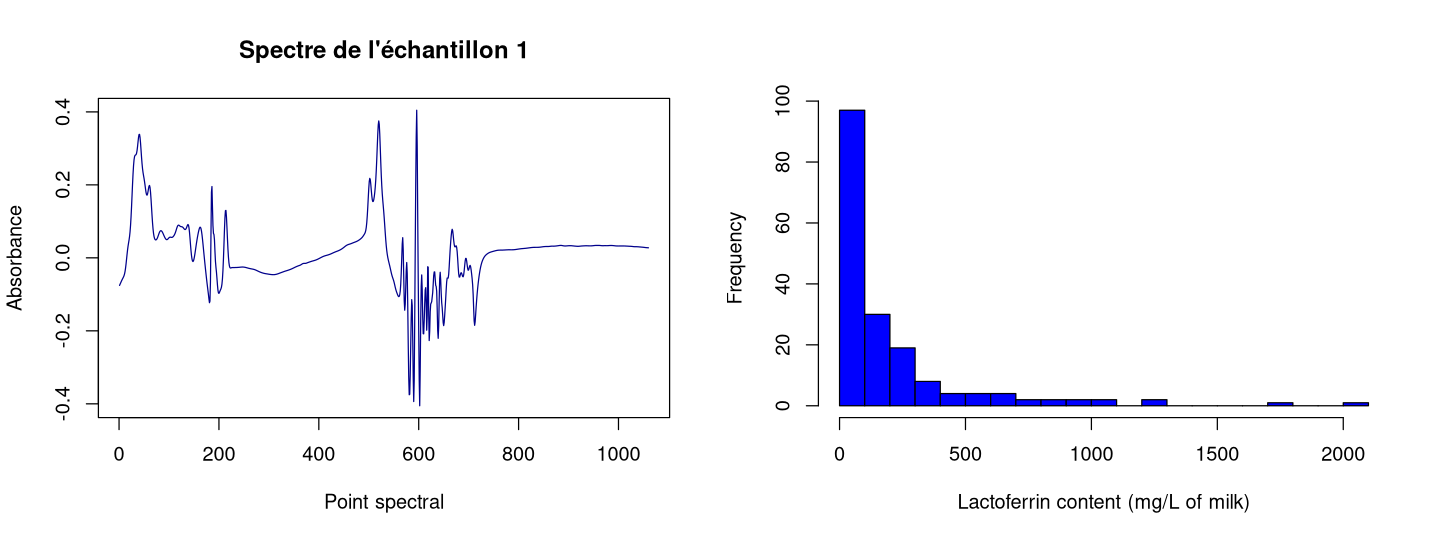

In [9]:
options(repr.plot.width = 12, repr.plot.height = 4.5)
par(mfrow = c(1, 2))   # 2 graphiques côte à côte
# Spectre du 1er échantillon : 1060 absorbances tracées en ligne
plot(as.numeric(lactoferrin[1, 2:1061]), type = "l", col = "darkblue",
     xlab = "Point spectral", ylab = "Absorbance", main = "Spectre de l'échantillon 1")
# Histogramme de la lactoferrine
hist(lactoferrin[, 1062], breaks = 20, col = "blue",
     xlab = "Lactoferrin content (mg/L of milk)", main = NULL)
par(mfrow = c(1, 1))   # remise à 1 graphique

### 0.7.7 Les packages

- Un package s'installe **une fois** : `install.packages("glmnet")` (déjà fait sur ce PC).
- Il se charge **à chaque session** : `library(glmnet)`.
- `nom_package::fonction()` appelle une fonction sans charger tout le package (ex. `corrplot::corrplot()`).

Packages utilisés dans le module :

| Package | Usage |
|---|---|
| `summarytools` | `descr()` : statistiques descriptives |
| `pander`, `knitr` | `pander()`, `kable()` : affichage de tableaux |
| `MASS` | `stepAIC()` : sélection backward/forward/stepwise |
| `olsrr` | `ols_step_all_possible()` : toutes les combinaisons de variables |
| `relaimpo` | `calc.relimp()` : importance relative des variables |
| `glmnet` | régressions Ridge, Lasso, Elastic Net |
| `corrplot` | visualisation de matrices de corrélation |
| `car` | `vif()` (complément) |

In [10]:
suppressPackageStartupMessages({
  library(summarytools); library(pander); library(knitr)
  library(MASS); library(olsrr); library(glmnet)
})
cat("Packages chargés.\n")

Packages chargés.


> **Attention** : `pander()` produit du **Markdown**. Dans RStudio/RMarkdown il est rendu en joli tableau ; dans Jupyter, il s'affiche en texte brut. Dans ce cours, on utilisera surtout `print()` ou `knitr::kable()`, ou cette astuce pour un rendu propre :

In [11]:
pander_md <- function(x, ...) IRdisplay::display_markdown(paste(capture.output(pander(x, ...)), collapse = "\n"))
pander_md(head(lactoferrin[, c(1, 2, 3, 1062)]))



| V1 |    V2    |    V3    | V1062 |
|:--:|:--------:|:--------:|:-----:|
| 1  | -0.07546 | -0.07229 | 16.24 |
| 2  | -0.08329 | -0.08006 | 185.3 |
| 3  | -0.06189 | -0.05941 | 193.3 |
| 4  | -0.06069 | -0.05818 | 125.8 |
| 5  | -0.05964 | -0.05696 | 16.63 |
| 6  | -0.09238 | -0.0887  |  108  |


### Exercice 0.3 : explorer le fichier
1. Combien d'échantillons ont une teneur en lactoferrine supérieure à 500 mg/L ?
2. Quel est l'identifiant (`V1`) de l'échantillon le plus riche en lactoferrine ?
3. Quelle est l'absorbance du point spectral n°713 (colonne `V714`) pour les 5 premiers échantillons ?

In [12]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
sum(lactoferrin[, 1062] > 500)               # 1. TRUE vaut 1, FALSE vaut 0 → somme = effectif
lactoferrin[which.max(lactoferrin[, 1062]), 1]   # 2. identifiant du maximum
lactoferrin[1:5, 714]                         # 3. point spectral 713 = colonne 714 (décalage de +1 dû à l'ID)
```

Le **décalage de +1** entre le numéro du point spectral et le numéro de colonne est un piège récurrent du module : la colonne 1 contient l'identifiant.

</details>

### Exercice 0.4 : `order()` et les plus grandes valeurs
On veut les **positions** des 3 échantillons les plus riches en lactoferrine et leurs teneurs. Utilise `order()` (sans argument `decreasing`), puis refais-le avec `order(..., decreasing = TRUE)`.

In [13]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
y <- lactoferrin[, 1062]
o <- order(y)                 # positions triées par ordre croissant
top3 <- o[(length(y) - 2):length(y)]   # les 3 dernières = les 3 plus grandes (dans l'ordre croissant)
top3
y[top3]
# Équivalent plus lisible
top3b <- order(y, decreasing = TRUE)[1:3]
y[top3b]
```

C'est exactement la logique utilisée plus tard pour sélectionner les points spectraux les plus corrélés : `ordercorrelation[1051:1060]` = les 10 dernières positions = les 10 plus fortes corrélations.

</details>

### Exercice 0.5 : spectre moyen
Calcule le **spectre moyen** (moyenne de chaque point spectral sur les 178 échantillons) et trace-le en ligne rouge, avec « Spectral data point » en abscisse et « Average value of absorbance » en ordonnée.

In [14]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
moyenne <- colMeans(lactoferrin[, 2:1061])   # ou apply(lactoferrin[, 2:1061], 2, mean)
plot(moyenne, type = "l", col = "red",
     xlab = "Spectral data point", ylab = "Average value of absorbance")
```

On retrouve le graphique des slides « Many variables, graphical representation ». Avec 1060 variables, un graphique est le seul moyen de « voir » les données.

</details>

### Questions de compréhension

1. Vrai ou faux : le Data Mining est un sous-ensemble du Machine Learning.
2. À quelle étape du KDD correspond la « calibration » ? Et la « validation » ?
3. Pourquoi le clustering est-il qualifié de non supervisé ?
4. Que renvoie `lactoferrin[, -c(1, 1062)]` ?

<details>
<summary><b>Voir les réponses</b></summary>

1. **Faux** : c'est l'inverse dans le cours, le Data Mining **utilise** des méthodes de Machine Learning (en plus de la statistique et de la gestion des données) ; la chimiométrie est elle-même un sous-groupe.
2. Calibration = étape **4** (*data mining*, choix et ajustement de la méthode) ; validation = étape **5** (*interpretation/evaluation* sur des données **indépendantes**).
3. Parce qu'il n'y a **pas de variable cible** : les groupes sont créés à partir des seules similarités entre échantillons.
4. Le data.frame **sans** l'identifiant ni la lactoferrine, c'est-à-dire uniquement les 1060 colonnes du spectre.

</details>

## Récapitulatif

- **Data Mining** : découvrir des relations dans les données (Statistique + ML + Data Management) pour produire une information utile. **ML** : apprendre sans être explicitement programmé (Samuel) ; apprendre de l'expérience E pour une tâche T mesurée par P (Mitchell). **Chimiométrie** : prédiction à partir de signaux électromagnétiques aux points adjacents corrélés.
- **KDD** : 0 objectif → 1 sélection → 2 nettoyage → 3 transformation → 4 data mining (**calibration**) → 5 interprétation/évaluation (**validation** sur données indépendantes), de manière itérative.
- **Régression** (y quantitative) et **classification** (y qualitative) sont **supervisées** ; le **clustering** est **non supervisé**.
- Jeux de données : `lactoferrin.csv` (ID, 1060 points spectraux, lactoferrine) et `fatty_acids.csv` (ID, SAT, MONO, POLY, 1060 points).

| Fonction | Rôle |
|---|---|
| `?f`, `getwd()`, `setwd()` | aide, dossier de travail |
| `read.table(file, sep, header)` | lire un fichier |
| `str`, `dim`, `nrow`, `ncol`, `head` | structure et dimensions |
| `df[i, j]`, `df[, -1]`, `df$col` | indexation |
| `data.frame`, `as.matrix`, `names()<-` | structures et noms |
| `c`, `seq`, `order`, `sort`, `which.max`, `apply`, `colMeans`, `paste0` | manipulations de vecteurs |
| `plot(type=)`, `hist`, `par(mfrow=)` | graphiques |
| `library`, `install.packages` | packages |
| `options(repr.plot.width/height)` | taille des figures (Jupyter) |

**Suite** : `01_Exploration_et_controle_des_donnees`, où l'on applique l'étape de *data cleaning* au jeu de données lactoferrine.